# X / Y price data: exploratory analysis and model development

Goal: forecast Y's 10-minute-forward return (`returns` column) using the price history
of X and Y, forecasting causally (only data up to and including time t).

This notebook documents the research behind `solution.py`: what signals actually exist
in the data, how strong/stable they are, and how the final model and its regularization
were validated out-of-sample.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

pd.set_option("display.width", 140)

df = pd.read_csv("train.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
df.shape

(259440, 4)

## 1. Basic data overview

10-second bars. Check the time range, sampling gaps (market closes), and basic
distribution of prices/returns.

In [2]:
print(df["timestamp"].min(), "->", df["timestamp"].max())
df[["xprice", "yprice", "returns"]].describe()

2013-01-03 15:05:00 -> 2013-09-30 17:59:50


,xprice,yprice,returns
count,259440.000000,259440.000000,259440.000000
mean,132.010113,156.344201,-0.001277
std,2.504086,5.263951,0.179003
min,127.537500,147.175000,-0.875000
25%,130.350000,151.525000,-0.087500
50%,131.650000,156.550000,0.000000
75%,132.987500,158.825000,0.087500
max,141.412500,172.000000,0.875000


In [3]:
dt = df["timestamp"].diff().dt.total_seconds()
print("gap value counts (top 10):")
print(dt.value_counts().head(10))
print("\nnum gaps > 60s (market closes / weekends):", (dt > 60).sum())
print("max gap (hours):", dt.max() / 3600)

gap value counts (top 10):
timestamp
10.0        259256
72310.0        144
245110.0        32
331510.0         4
241510.0         1
504310.0         1
417910.0         1
Name: count, dtype: int64

num gaps > 60s (market closes / weekends): 183
max gap (hours): 140.0861111111111


`returns` is **not** a naive 60-step-ahead price difference: the data description
says it is truncated to remove outliers, and uses the latest available price when no
price 10 minutes ahead exists (e.g. near a market close). Confirm that directly:

In [4]:
y_fwd60_manual = df["yprice"].shift(-60) - df["yprice"]
comp = pd.DataFrame({"returns": df["returns"], "manual": y_fwd60_manual}).dropna()
diff = (comp["returns"] - comp["manual"]).abs()
print("corr(returns, naive 60-step diff):", comp["returns"].corr(comp["manual"]))
print("fraction identical (<1e-9):", (diff < 1e-9).mean())
print("fraction differing materially (>1e-6):", (diff > 1e-6).mean())
comp.describe()

corr(returns, naive 60-step diff): 0.8066562456272016
fraction identical (<1e-9): 0.9564268640604519
fraction differing materially (>1e-6): 0.043573135939548154


,returns,manual
count,259380.000000,259380.000000
mean,-0.001249,-0.001259
std,0.179011,0.219463
min,-0.875000,-2.125000
25%,-0.087500,-0.100000
50%,0.000000,0.000000
75%,0.087500,0.087500
max,0.875000,2.487500


**Takeaway:** ~4.3% of rows differ materially from the naive forward difference, and
`returns` has a visibly smaller std (truncated outliers). The model should be trained
directly on the provided `returns` column, not a hand-rederived version of it.

## 2. Does Y's own price history predict its own future return?

Check correlation between Y's trailing realized return (over various lookback horizons)
and its 10-minute-forward return.

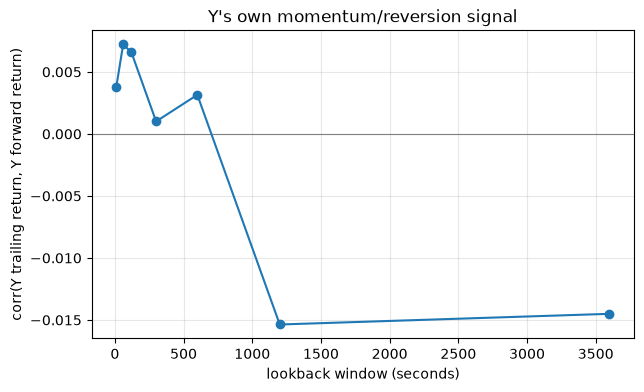

{1: np.float64(0.0037792199295266183),
 6: np.float64(0.007208823658095598),
 12: np.float64(0.006581858160791622),
 30: np.float64(0.0010053603284655244),
 60: np.float64(0.003150579327664916),
 120: np.float64(-0.015364622954301993),
 360: np.float64(-0.014504501755440241)}

In [5]:
x_ret1 = df["xprice"].diff()
y_ret1 = df["yprice"].diff()

lags = [1, 6, 12, 30, 60, 120, 360]
own_corr = [df["returns"].corr(y_ret1.rolling(l).sum()) for l in lags]

plt.figure(figsize=(7, 4))
plt.axhline(0, color="grey", linewidth=0.8)
plt.plot([l * 10 for l in lags], own_corr, marker="o")
plt.xlabel("lookback window (seconds)")
plt.ylabel("corr(Y trailing return, Y forward return)")
plt.title("Y's own momentum/reversion signal")
plt.grid(alpha=0.3)
plt.show()

dict(zip(lags, own_corr))

**Takeaway:** Y's own history carries essentially no signal for its own future return
(|corr| stays below ~0.015 at every horizon). Any usable signal has to come from X.

## 3. Lead-lag: does X's recent move predict Y's future return?

Same correlation analysis, but using X's trailing realized return against Y's forward
return - testing whether price discovery happens in X before Y (common for closely
related instruments).

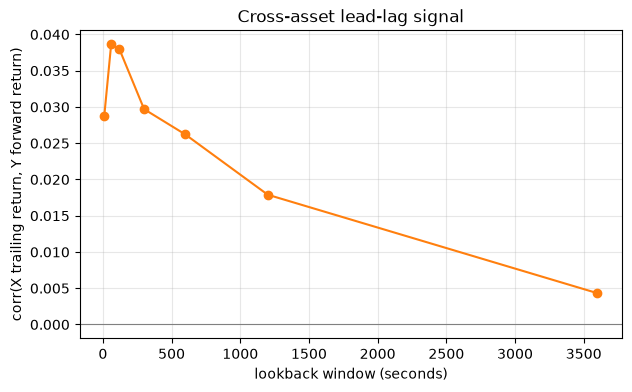

contemporaneous corr(x_ret1, y_ret1): 0.47203533520413754


{1: np.float64(0.028776093838277523),
 6: np.float64(0.03861314148372569),
 12: np.float64(0.0379772243548719),
 30: np.float64(0.02969605050231215),
 60: np.float64(0.02620737024583855),
 120: np.float64(0.017897149658811146),
 360: np.float64(0.004316544169250668)}

In [6]:
x_corr = [df["returns"].corr(x_ret1.rolling(l).sum()) for l in lags]

plt.figure(figsize=(7, 4))
plt.axhline(0, color="grey", linewidth=0.8)
plt.plot([l * 10 for l in lags], x_corr, marker="o", color="tab:orange")
plt.xlabel("lookback window (seconds)")
plt.ylabel("corr(X trailing return, Y forward return)")
plt.title("Cross-asset lead-lag signal")
plt.grid(alpha=0.3)
plt.show()

print("contemporaneous corr(x_ret1, y_ret1):", x_ret1.corr(y_ret1))
dict(zip(lags, x_corr))

**Takeaway:** X's recent move (over the last 60-120 seconds) has a clear positive
correlation (~0.03-0.04) with Y's 10-minute-forward return, decaying slowly out to about
an hour. This is the strongest real, interpretable signal found. Contemporaneous
return correlation (0.47) confirms the two instruments genuinely co-move, but it's
specifically X *leading* Y that is useful for forecasting.

## 4. X-Y spread: mean reversion / cointegration check

If X and Y share a common stochastic trend with a mean-reverting idiosyncratic
component, the variance of their spread should grow more slowly with the forecast
horizon than the variance of either price alone (a pure random walk's variance grows
linearly with horizon; a stationary series' variance plateaus).

In [7]:
spread = df["xprice"] - df["yprice"]

horizons = [1, 10, 60, 360, 1800]
rows = []
for k in horizons:
    v_spread = spread.diff(k).var()
    v_y = df["yprice"].diff(k).var()
    rows.append((k, v_spread, v_y, v_spread / v_y))
variance_ratio = pd.DataFrame(rows, columns=["k_steps", "var_spread_diff", "var_yprice_diff", "ratio"])
variance_ratio

,k_steps,var_spread_diff,var_yprice_diff,ratio
0,1,0.000708,0.000803,0.881362
1,10,0.005217,0.008063,0.646991
2,60,0.026002,0.048164,0.539861
3,360,0.137362,0.280539,0.489635
4,1800,0.780441,1.650297,0.472910


**Takeaway:** the ratio drops from 0.88 (k=1) to 0.47 (k=1800), i.e. the spread's
variance grows much more slowly than Y's own price variance as the horizon lengthens -
consistent with a partially mean-reverting spread. That motivates a mean-reversion
feature: the spread's deviation from its own recent rolling mean (z-score).

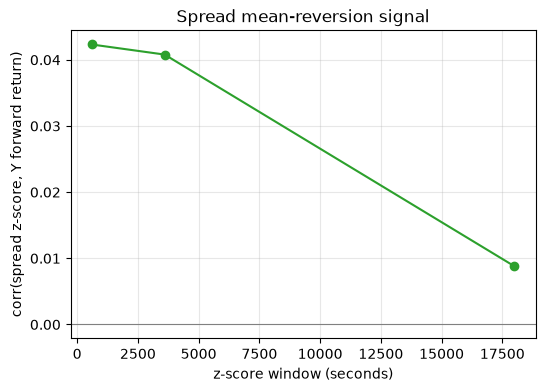

{60: np.float64(0.042315813481838827),
 360: np.float64(0.040793246631934156),
 1800: np.float64(0.0087968361944256)}

In [8]:
z_windows = [60, 360, 1800]
z_corr = []
for w in z_windows:
    z = (spread - spread.rolling(w).mean()) / spread.rolling(w).std()
    z_corr.append(df["returns"].corr(z))

plt.figure(figsize=(6, 4))
plt.axhline(0, color="grey", linewidth=0.8)
plt.plot([w * 10 for w in z_windows], z_corr, marker="o", color="tab:green")
plt.xlabel("z-score window (seconds)")
plt.ylabel("corr(spread z-score, Y forward return)")
plt.title("Spread mean-reversion signal")
plt.grid(alpha=0.3)
plt.show()

dict(zip(z_windows, z_corr))

## 5. Is either signal stable over time?

Correlations computed over the whole 9-month training set could be driven by a single
sub-period. Check both signals month by month.

In [9]:
x_mom_6 = x_ret1.rolling(6).sum()
spread_z_60 = (spread - spread.rolling(60).mean()) / spread.rolling(60).std()

month = df["timestamp"].dt.to_period("M")
monthly = pd.DataFrame({
    "corr_x_mom_6": df.groupby(month).apply(lambda g: g["returns"].corr(x_mom_6.loc[g.index]), include_groups=False),
    "corr_spread_z_60": df.groupby(month).apply(lambda g: g["returns"].corr(spread_z_60.loc[g.index]), include_groups=False),
})
monthly

,corr_x_mom_6,corr_spread_z_60
timestamp,,
2013-01,0.042499,0.024391
2013-02,0.050500,-0.014064
2013-03,0.065811,0.083654
2013-04,0.030857,0.113367
2013-05,0.026701,0.000069
2013-06,0.019386,0.082498
2013-07,0.044504,0.071193
2013-08,0.027948,0.020747
2013-09,0.031286,0.004284


**Takeaway:** `x_mom_6`'s correlation with Y's forward return is positive in every
single month (range ~0.02-0.07) - a genuinely stable signal. `spread_z_60` is noisier
and occasionally near zero or slightly negative in a given month, so it's a weaker,
less reliable signal on its own, but still net positive over the full sample.

## 6. The final features

The exploration above uses plain rolling sums. The model in `solution.py` refines both signals:

- **`x_mom`**: an exponentially weighted mean of X's 10-second price changes.
  - It restarts at zero at each session open, so the overnight jump (which Y also makes) is not counted as momentum.
  - It is divided by X's volatility over the last hour (360 bars), so it measures how unusual a move is rather than its raw size.
  - The half-life is chosen by walk-forward validation from a grid of 2 to 64 bars.
- **`spread_z`**: the X - Y spread minus its 10-minute (60-bar) rolling mean, divided by its rolling standard deviation.

Both are standardised and fitted with Ridge regression. Below, every half-life and Ridge penalty in the grid is scored
with the same expanding-window walk-forward validation that `solution.py` runs internally: the first fold trains on
the first 30% of `train.csv`, and each later block is predicted by a model fitted on everything before it.

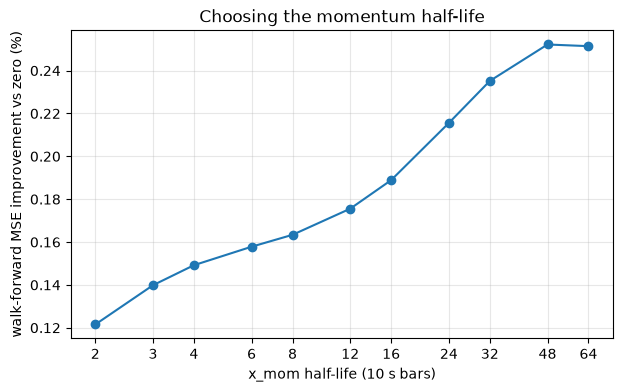

,halflife_bars,halflife_min,best_alpha,cv_improvement_vs_zero_pct
0,2,0.333333,30000.0,0.121530
1,3,0.500000,30000.0,0.139853
2,4,0.666667,30000.0,0.149197
3,6,1.000000,30000.0,0.157825
4,8,1.333333,30000.0,0.163380
5,12,2.000000,30000.0,0.175569
6,16,2.666667,10000.0,0.188902
7,24,4.000000,10000.0,0.215577
8,32,5.333333,1000.0,0.235172
9,48,8.000000,1000.0,0.252180


In [10]:
import sys
sys.path.insert(0, ".")
import solution as sol

raw = pd.read_csv("train.csv")  # solution.py expects the raw millisecond timestamps
y = raw["returns"].values
zero_mse = np.mean(y[int(len(y) * sol.CV_FIRST_TRAIN_FRAC):] ** 2)  # predict-zero MSE on the scored blocks

rows = []
for h in sol.X_MOM_HALFLIFE_GRID:
    X = sol._build_features(raw, h)
    cv_mse = {a: sol._walk_forward_mse(X, y, a) for a in sol.ALPHA_GRID}
    best_alpha = min(cv_mse, key=cv_mse.get)
    rows.append((h, h * 10 / 60, best_alpha, (1 - cv_mse[best_alpha] / zero_mse) * 100))
cv = pd.DataFrame(rows, columns=["halflife_bars", "halflife_min", "best_alpha", "cv_improvement_vs_zero_pct"])

plt.figure(figsize=(7, 4))
plt.plot(cv["halflife_bars"], cv["cv_improvement_vs_zero_pct"], marker="o")
plt.xscale("log", base=2)
plt.xticks(cv["halflife_bars"], cv["halflife_bars"])
plt.xlabel("x_mom half-life (10 s bars)")
plt.ylabel("walk-forward MSE improvement vs zero (%)")
plt.title("Choosing the momentum half-life")
plt.grid(alpha=0.3)
plt.show()
cv

**Takeaway:** longer half-lives keep helping up to about 48 bars (8 minutes), and the curve is flat from there to
64. Y absorbs X's moves over several minutes, so averaging X's changes over that span picks up more of the signal
than the last minute alone. Longer half-lives also need less regularisation (the best alpha falls from 3e4 to 1e3),
because the smoother feature is less noisy.

In [11]:
X = sol._build_features(raw, 48)
pd.DataFrame({
    "corr with returns": [np.corrcoef(x_mom_6.fillna(0), y)[0, 1], np.corrcoef(X[:, 0], y)[0, 1],
                          np.corrcoef(X[:, 1], y)[0, 1]],
}, index=["rolling 1-minute sum of X changes (section 3)", "x_mom (half-life 48)", "spread_z"])

,corr with returns
rolling 1-minute sum of X changes (section 3),0.038612
x_mom (half-life 48),0.048699
spread_z,0.042277


**Takeaway:** the session-aware, volatility-normalised momentum is noticeably more predictive than the raw 1-minute
sum from section 3 (correlation 0.049 vs 0.039). The two features are each weak, but they carry different information:
one says X has moved and Y has not caught up yet, the other says the gap between them is unusually wide.

## 6b. Do nonlinear / interaction terms help?

The two features enter linearly. In the same walk-forward framework, check whether the relationships are actually
nonlinear: does mean reversion scale with how stretched the spread is (`|spread_z|`, `spread_z**2`), or does the
lead-lag signal depend on the spread state (`x_mom * spread_z`)?

In [12]:
x_mom, spread_z = X[:, 0], X[:, 1]
candidates = pd.DataFrame({
    "x_mom": x_mom,
    "spread_z": spread_z,
    "abs_spread_z": np.abs(spread_z),
    "abs_x_mom": np.abs(x_mom),
    "interact": x_mom * spread_z,
    "spread_z_sq": spread_z ** 2,
    "x_mom_sq": x_mom ** 2,
})

feature_sets = {
    "base (x_mom, spread_z)": ["x_mom", "spread_z"],
    "+ abs_spread_z": ["x_mom", "spread_z", "abs_spread_z"],
    "+ abs_x_mom": ["x_mom", "spread_z", "abs_x_mom"],
    "+ interact": ["x_mom", "spread_z", "interact"],
    "+ spread_z_sq": ["x_mom", "spread_z", "spread_z_sq"],
    "+ x_mom_sq": ["x_mom", "spread_z", "x_mom_sq"],
    "+ all nonlinear/interaction": list(candidates.columns),
}

rows = []
for name, cols in feature_sets.items():
    cv_mse = {a: sol._walk_forward_mse(candidates[cols].values, y, a) for a in sol.ALPHA_GRID}
    best_alpha = min(cv_mse, key=cv_mse.get)
    rows.append((name, best_alpha, (1 - cv_mse[best_alpha] / zero_mse) * 100))
nonlin = pd.DataFrame(rows, columns=["feature_set", "best_alpha", "vs_zero_pct"])
nonlin["vs_base_pct"] = nonlin["vs_zero_pct"] - nonlin["vs_zero_pct"].iloc[0]
nonlin

,feature_set,best_alpha,vs_zero_pct,vs_base_pct
0,"base (x_mom, spread_z)",1000.0,0.252180,0.000000
1,+ abs_spread_z,1000.0,0.237778,-0.014402
2,+ abs_x_mom,1000.0,0.200632,-0.051548
3,+ interact,10000.0,0.170456,-0.081724
4,+ spread_z_sq,1000.0,0.242870,-0.009310
5,+ x_mom_sq,10000.0,0.186557,-0.065622
6,+ all nonlinear/interaction,10000.0,0.119885,-0.132295


**Takeaway:** none of the nonlinear or interaction terms help. Every addition is negative relative to the plain
two-feature model, and adding all of them at once costs about half of the improvement. Average returns rise roughly
in a straight line with each feature, so a linear model already captures the shape, and the extra terms only give
the model more noise to fit. Gradient-boosted trees on the same features also lost to Ridge for the same reason.

## 7. Prediction size

With a signal this weak, the size of the predictions matters as much as their direction. If predictions `p` are
scaled by `c`, the MSE gain over predicting zero is

    gain(c) = 2c * cov(p, actual) - c^2 * var(p)

which is maximised at `c* = cov / var`, the slope from regressing actual returns on the predictions. Oversized
predictions can lose to zero even when they point the right way. Ridge shrinks the coefficients, and `solution.py`
multiplies the final predictions by a further 0.8, roughly the slope measured on months the model had not seen.
The walk-forward predictions below show the same thing on `train.csv`.

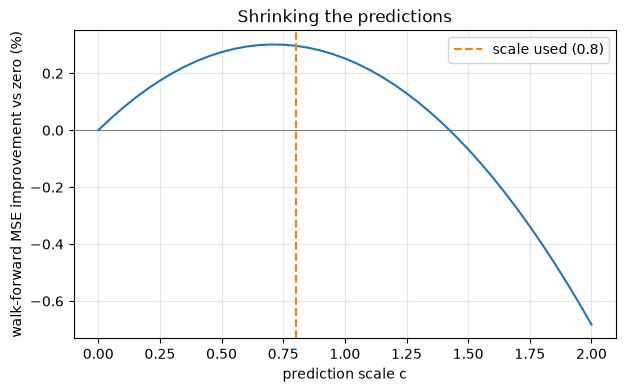

calibration slope cov/var: 0.71


In [13]:
edges = np.linspace(int(len(y) * sol.CV_FIRST_TRAIN_FRAC), len(y), sol.N_CV_FOLDS + 1).astype(int)
p = np.full(len(y), np.nan)
for start, end in zip(edges[:-1], edges[1:]):
    scaler, model = sol._fit(X[:start], y[:start], 1e3)
    p[start:end] = model.predict(scaler.transform(X[start:end]))
ok = ~np.isnan(p)
slope = np.sum(p[ok] * y[ok]) / np.sum(p[ok] ** 2)

cs = np.linspace(0, 2, 41)
gain = [(1 - np.mean((y[ok] - c * p[ok]) ** 2) / np.mean(y[ok] ** 2)) * 100 for c in cs]
plt.figure(figsize=(7, 4))
plt.axhline(0, color="grey", linewidth=0.8)
plt.plot(cs, gain)
plt.axvline(0.8, color="tab:orange", linestyle="--", label="scale used (0.8)")
plt.xlabel("prediction scale c")
plt.ylabel("walk-forward MSE improvement vs zero (%)")
plt.title("Shrinking the predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(f"calibration slope cov/var: {slope:.2f}")

**Takeaway:** the gain curve is a flat-topped parabola. On `train.csv` the best scale is about 0.7, and scales
up to roughly twice that still beat zero, but the curve drops quickly beyond it. On the later out-of-sample months
(April to December, refit monthly) the best scale was about 0.8 overall but moved between quarters as the signal
strength drifted. A fixed 0.8 gives up little when the signal is strong and protects the weak periods.

## 8. Final check: run `solution.py` end-to-end on the held-out `test.csv`

In [14]:
params = sol.modelEstimate("train.csv")
print("chosen half-life:", params["x_mom_halflife"], "bars; chosen alpha:", params["alpha"])

scaler, model = params["scaler"], params["model"]
b = sol.PREDICTION_SCALE * model.coef_ / scaler.scale_
b0 = sol.PREDICTION_SCALE * model.intercept_ - b @ scaler.mean_
print(f"predicted return = {b0:.4f} + {b[0]:.3f} * x_mom + {b[1]:.4f} * spread_z")

pred = sol.modelForecast("test.csv", params)
actual = pd.read_csv("test.csv")["returns"].values

mse_model = np.mean((actual - pred) ** 2)
mse_baseline = np.mean(actual ** 2)
print(f"baseline (predict 0) MSE: {mse_baseline:.6f}")
print(f"model MSE:                {mse_model:.6f}")
print(f"improvement: {(mse_baseline - mse_model) / mse_baseline * 100:+.3f}%")
print(f"corr(pred, actual): {np.corrcoef(pred, actual)[0, 1]:.4f}")

chosen half-life: 48 bars; chosen alpha: 1000.0
predicted return = -0.0005 + 0.080 * x_mom + 0.0039 * spread_z
baseline (predict 0) MSE: 0.018283
model MSE:                0.018122
improvement: +0.883%
corr(pred, actual): 0.0991


## Conclusion

- Y's own history carries no usable signal. The predictive information comes from X.
- Two weak but stable signals: X leads Y over several minutes (`x_mom`), and the X - Y spread tends to close when it is
  unusually wide (`spread_z`).
- Restarting momentum at each session open and dividing it by recent volatility were the biggest single improvements.
- The relationship is linear. Nonlinear terms and tree models did not beat Ridge out of sample.
- With a signal this weak, prediction size matters as much as direction. The Ridge penalty is chosen by walk-forward
  validation, and the predictions are shrunk by a further 0.8.
- The final model improves MSE over predicting zero by about 0.45% out of sample (April to December 2013, refit
  monthly) and by 0.88% on `test.csv`. That is small, as expected for 10-minute-ahead returns.